# Lab: ANN classification of satellite-image patches, Task 1 (urban vs forest)

This notebook reuses the data from the previous lab (`forest.jpg`, `urban.jpg`, `test.jpg`), but the question changes:
before, we classified every **pixel** from its RGB colour (Bayes, kNN); now we classify a whole **patch** with an ANN.

## 1. How do we pose the task as a function?
We want a function

$$ f(\text{patch}) \;\to\; p \in [0,1], \qquad p = P(\text{urban} \mid \text{patch}) $$

* **Input:** one square patch of `PATCH x PATCH` pixels with 3 colour channels, scaled to 0..1. That is `PATCH*PATCH*3` numbers.
* **Output:** one number. `p > 0.5` means *urban*, otherwise *forest*.

Since the task is a function from numbers to a number, a neural network can learn it from labelled examples.

## 2. Training data
* Cut `forest.jpg` into non-overlapping patches and tag each one `forest` (0). Do the same for `urban.jpg` (tag 1). One patch is one example.
* Random stratified split of the patches: **70 % train, 15 % validation, 15 % test**. Validation is used for early stopping and for choosing the best model. Test is used only for the final numbers.
* The training patches are also flipped and rotated (8 variants each). This helps because we have few patches, and it is legitimate because a rotated forest is still a forest.
* In the *test phase* the trained network assigns a tag to every new patch of `test.jpg`.

## 3. Baseline architecture
`patch -> AveragePooling (shrink to about 50x50) -> Flatten -> Dense(32, relu) -> Dense(1, sigmoid)`, with binary cross-entropy loss and Adam.

* One hidden layer is the simplest network that is not just logistic regression.
* The sigmoid output gives a probability. Cross-entropy is the matching loss for a yes/no tag. (For the diode we used a linear output and MSE because the target was a number.)

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

%matplotlib inline
FOREST, URBAN = 0, 1                                            # numerical labels for the two classes
RED, BLUE = np.array([220, 40, 40]), np.array([40, 80, 220])    # forest -> red, urban -> blue

DATA_DIR = r"C:\Users\ada\Downloads"   # folder containing forest.jpg, urban.jpg, test.jpg
MAXSIDE  = None    # None = keep full resolution. The ANN does not need the shrinking that kNN needed.
PATCH    = 200     # patch size from the lab text; reduced automatically if the photos are too small
MIN_PATCHES = 30   # we want at least this many patches per class
AUGMENT  = True    # flips + rotations of the TRAINING patches only
SEEDS    = (0, 1, 2)   # every experiment is repeated with these random initialisations
EPOCHS, BATCH = 80, 16

## Load the images (same as in the previous lab)

In [2]:
def load(name):
    path = os.path.join(DATA_DIR, name)
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Not found: {path}")
    im = Image.open(path).convert("RGB")             # force 3 channels, ignore alpha if present
    if MAXSIDE and max(im.size) > MAXSIDE:
        im.thumbnail((MAXSIDE, MAXSIDE))             # keep aspect ratio
    return np.asarray(im, float)

forest_img = load("forest.jpg")
urban_img  = load("urban.jpg")
test_img   = load("test.jpg")
print("Loaded:", forest_img.shape, urban_img.shape, test_img.shape)

Loaded: (285, 447, 3) (371, 642, 3) (415, 631, 3)


## Create the training data: cut the photos into patches
The photos from the previous lab may be small. If there are fewer than `MIN_PATCHES` patches per class at 200x200, the code halves the patch size until there are enough (and says so). A 200x200 patch from a 300x450 photo would give only two examples per class, and nothing can be learned or tested from that.

Photos too small for enough patches -> PATCH reduced to 100
Photos too small for enough patches -> PATCH reduced to 50
PATCH = 50: 40 forest patches, 84 urban patches
patches  train / val / test: 86 19 19
training examples after augmentation: 688


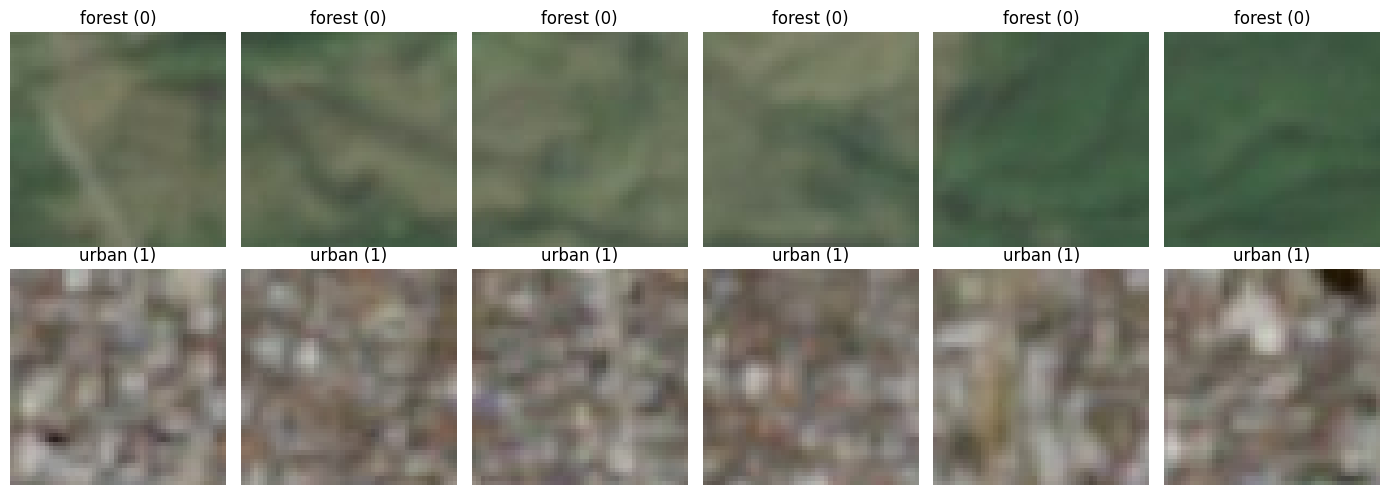

In [3]:
def cut_patches(img, p):
    # non-overlapping p x p patches from the whole image
    H, W = img.shape[:2]
    return np.array([img[r:r + p, c:c + p] for r in range(0, H - p + 1, p) for c in range(0, W - p + 1, p)])

def n_patches(img, p):
    return (img.shape[0] // p) * (img.shape[1] // p)

while PATCH > 32 and min(n_patches(forest_img, PATCH), n_patches(urban_img, PATCH)) < MIN_PATCHES:
    PATCH //= 2
    print(f"Photos too small for enough patches -> PATCH reduced to {PATCH}")

Pf, Pu = cut_patches(forest_img, PATCH), cut_patches(urban_img, PATCH)
print(f"PATCH = {PATCH}: {len(Pf)} forest patches, {len(Pu)} urban patches")
assert min(len(Pf), len(Pu)) >= 6, "Too few patches: use bigger photos (set MAXSIDE=None) or a smaller PATCH."

X = np.concatenate([Pf, Pu]) / 255.0                       # scale to 0..1
y = np.r_[np.full(len(Pf), FOREST), np.full(len(Pu), URBAN)].astype("float32")

# stratified random split 70/15/15
rng = np.random.default_rng(0)
tr, va, te = [], [], []
for c in (FOREST, URBAN):
    idx = rng.permutation(np.where(y == c)[0]); n = len(idx)
    a, b = max(int(0.70 * n), 1), max(int(0.85 * n), 2)
    tr += list(idx[:a]); va += list(idx[a:b]); te += list(idx[b:])
Xtr, ytr, Xva, yva, Xte, yte = X[tr], y[tr], X[va], y[va], X[te], y[te]
print("patches  train / val / test:", len(ytr), len(yva), len(yte))

def dihedral(P):
    # the 8 flips/rotations of every patch
    out = []
    for k in range(4):
        r = np.rot90(P, k, axes=(1, 2)); out += [r, r[:, :, ::-1]]
    return np.concatenate(out)

Xtr_raw, ytr_raw = Xtr, ytr                 # un-augmented copy (used by the Bayes reference below)
if AUGMENT:
    Xtr, ytr = dihedral(Xtr), np.tile(ytr, 8)
print("training examples after augmentation:", len(ytr))

# a few example patches
fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for j in range(6):
    ax[0, j].imshow(Pf[j % len(Pf)].astype(np.uint8)); ax[0, j].set_title("forest (0)")
    ax[1, j].imshow(Pu[j % len(Pu)].astype(np.uint8)); ax[1, j].set_title("urban (1)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## Model builder and experiment runner
Two kinds of input are possible:
* `pixels`: all pixels of the patch (shrunk by average pooling so that training stays fast),
* `summary`: only 6 numbers per patch, the mean and standard deviation of R, G and B. This is close to what the Bayes classifier of the previous lab "sees".

In [4]:
POOL = max(1, PATCH // 50)      # 200 -> pool 4 -> 50x50 input; smaller patches are not pooled

def summary_features(P):
    return np.concatenate([P.mean(axis=(1, 2)), P.std(axis=(1, 2))], axis=1)    # 6 numbers per patch

def make_optimizer(name, lr):
    return {"adam": tf.keras.optimizers.Adam, "sgd": tf.keras.optimizers.SGD,
            "rmsprop": tf.keras.optimizers.RMSprop}[name](lr)

def build(cfg):
    if cfg["input"] == "pixels":
        layers = [tf.keras.Input(shape=(PATCH, PATCH, 3))]
        if POOL > 1:
            layers.append(tf.keras.layers.AveragePooling2D(POOL))
        layers.append(tf.keras.layers.Flatten())
    else:
        layers = [tf.keras.Input(shape=(6,))]
    for units in cfg["hidden"]:
        layers.append(tf.keras.layers.Dense(units, activation=cfg.get("act", "relu")))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))       # probability of "urban"
    m = tf.keras.Sequential(layers)
    m.compile(loss="binary_crossentropy", optimizer=make_optimizer(cfg["opt"], cfg["lr"]), metrics=["accuracy"])
    return m

def run(cfg, seed):
    tf.keras.utils.set_random_seed(seed)
    if cfg["input"] == "pixels":
        prep = lambda P: P
    else:
        f = summary_features(Xtr); mu, sd = f.mean(0), f.std(0) + 1e-6      # statistics from TRAIN only
        prep = lambda P: (summary_features(P) - mu) / sd
    model = build(cfg)
    stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(prep(Xtr), ytr, validation_data=(prep(Xva), yva), epochs=EPOCHS,
                  batch_size=BATCH, callbacks=[stop], verbose=0)
    out = dict(train_acc=model.evaluate(prep(Xtr_raw), ytr_raw, verbose=0)[1],
               val_acc=model.evaluate(prep(Xva), yva, verbose=0)[1],
               test_acc=model.evaluate(prep(Xte), yte, verbose=0)[1],
               epochs=len(h.history["loss"]), seconds=time.time() - t0,
               params=model.count_params())
    return out, h.history, (lambda P: model.predict(prep(P), verbose=0)[:, 0])

## The permutations
Each experiment changes **one** thing relative to the baseline E1, so we can see what caused a difference.
Each is repeated with 3 random initialisations, because with few patches a single run is mostly luck.

In [5]:
experiments = [
    dict(name="E1 baseline: pixels, 32 relu, adam 1e-3", input="pixels",  hidden=[32],     opt="adam", lr=1e-3),
    dict(name="E2 more nodes: 128 relu",                 input="pixels",  hidden=[128],    opt="adam", lr=1e-3),
    dict(name="E3 more layers: 64-32 relu",              input="pixels",  hidden=[64, 32], opt="adam", lr=1e-3),
    dict(name="E4 optimiser: SGD 1e-2",                  input="pixels",  hidden=[32],     opt="sgd",  lr=1e-2),
    dict(name="E5 input: mean/std RGB (6 numbers), 16",  input="summary", hidden=[16],     opt="adam", lr=1e-3),
    dict(name="E6 activation: tanh, 32",                 input="pixels",  hidden=[32],     opt="adam", lr=1e-3, act="tanh"),
]

results, histories, predictors = {}, {}, {}
for cfg in experiments:
    runs = []
    for s in SEEDS:
        r, h, pred_fn = run(cfg, s)
        runs.append(r)
        if s == SEEDS[0]:
            histories[cfg["name"]], predictors[cfg["name"]] = h, pred_fn      # keep the first run for plots/maps
    results[cfg["name"]] = {k: (np.mean([r[k] for r in runs]), np.std([r[k] for r in runs])) for k in runs[0]}
    print(f"{cfg['name']:<46} val {results[cfg['name']]['val_acc'][0]:.3f}   test {results[cfg['name']]['test_acc'][0]:.3f}")

E1 baseline: pixels, 32 relu, adam 1e-3        val 1.000   test 1.000
E2 more nodes: 128 relu                        val 1.000   test 1.000
E3 more layers: 64-32 relu                     val 1.000   test 1.000
E4 optimiser: SGD 1e-2                         val 1.000   test 1.000
E5 input: mean/std RGB (6 numbers), 16         val 1.000   test 1.000
E6 activation: tanh, 32                        val 0.684   test 0.684


## Reference: Bayes classifier on the patch's mean colour
The same Gaussian Bayes idea as in the previous lab, but now on the mean RGB of a patch (3 numbers) instead of one pixel.
No iterative training, only a mean and covariance per class.

In [6]:
def fit_gaussian(F):
    mu = F.mean(0); Fc = F - mu
    return mu, Fc.T @ Fc / len(F) + 1e-6 * np.eye(F.shape[1])

def log_gauss(F, mu, S):
    d = F - mu
    maha = np.einsum("ni,ij,nj->n", d, np.linalg.inv(S), d)
    return -0.5 * (maha + np.log(np.linalg.det(S)) + F.shape[1] * np.log(2 * np.pi))

mean_rgb = lambda P: P.mean(axis=(1, 2))
mu_f, S_f = fit_gaussian(mean_rgb(Xtr_raw[ytr_raw == FOREST]))
mu_u, S_u = fit_gaussian(mean_rgb(Xtr_raw[ytr_raw == URBAN]))
prior_f = (ytr_raw == FOREST).mean()

def bayes_patch(P):
    llr = log_gauss(mean_rgb(P), mu_f, S_f) - log_gauss(mean_rgb(P), mu_u, S_u)
    return np.where(llr > np.log((1 - prior_f) / prior_f), FOREST, URBAN)

bayes_val  = float((bayes_patch(Xva) == yva).mean())
bayes_test = float((bayes_patch(Xte) == yte).mean())
print(f"Bayes (mean RGB):  val acc {bayes_val:.3f}   test acc {bayes_test:.3f}")

Bayes (mean RGB):  val acc 1.000   test acc 1.000


## Consolidated findings

Experiment                                       params  epochs  train acc       val acc      test acc  time [s]
E1 baseline: pixels, 32 relu, adam 1e-3          240065      80      1.000   1.000 ±0.000   1.000 ±0.000      40.0
E2 more nodes: 128 relu                          960257      80      1.000   1.000 ±0.000   1.000 ±0.000      81.1
E3 more layers: 64-32 relu                       482177      80      1.000   1.000 ±0.000   1.000 ±0.000      41.1
E4 optimiser: SGD 1e-2                           240065      80      1.000   1.000 ±0.000   1.000 ±0.000      16.5
E5 input: mean/std RGB (6 numbers), 16              129      80      1.000   1.000 ±0.000   1.000 ±0.000      13.6
E6 activation: tanh, 32                          240065      39      0.674   0.684 ±0.000   0.684 ±0.000      16.8
Reference: Bayes on mean RGB                          -       -          -         1.000         1.000         -

(± = standard deviation over 3 random initialisations; 19 test patches, so one patc

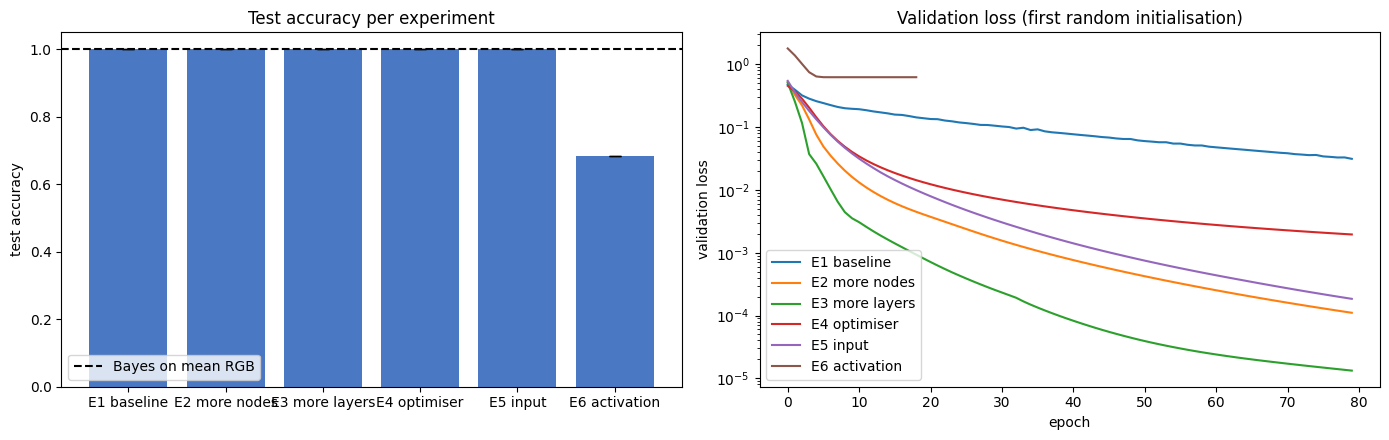

In [7]:
print(f"{'Experiment':<46}{'params':>9}{'epochs':>8}{'train acc':>11}{'val acc':>14}{'test acc':>14}{'time [s]':>10}")
for n, r in results.items():
    print(f"{n:<46}{r['params'][0]:>9.0f}{r['epochs'][0]:>8.0f}{r['train_acc'][0]:>11.3f}"
          f"{r['val_acc'][0]:>8.3f} ±{r['val_acc'][1]:.3f}{r['test_acc'][0]:>8.3f} ±{r['test_acc'][1]:.3f}{r['seconds'][0]:>10.1f}")
print(f"{'Reference: Bayes on mean RGB':<46}{'-':>9}{'-':>8}{'-':>11}{bayes_val:>14.3f}{bayes_test:>14.3f}{'-':>10}")
print(f"\n(± = standard deviation over {len(SEEDS)} random initialisations; {len(yte)} test patches, so one patch = {100/len(yte):.1f} percentage points)")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
names = list(results)
ax[0].bar(range(len(names)), [results[n]["test_acc"][0] for n in names],
          yerr=[results[n]["test_acc"][1] for n in names], capsize=4, color="#4a78c2")
ax[0].axhline(bayes_test, color="k", ls="--", label="Bayes on mean RGB")
ax[0].set_xticks(range(len(names))); ax[0].set_xticklabels([n.split(":")[0] for n in names])
ax[0].set_ylabel("test accuracy"); ax[0].set_ylim(0, 1.05); ax[0].legend(); ax[0].set_title("Test accuracy per experiment")
for n in names:
    ax[1].plot(histories[n]["val_loss"], label=n.split(":")[0])
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation loss"); ax[1].set_yscale("log")
ax[1].legend(); ax[1].set_title("Validation loss (first random initialisation)")
plt.tight_layout(); plt.show()

## Test phase: tag every patch of the new image
The network that is best on the **validation** patches (not on the test patches, otherwise we would be choosing with the test answers) slides over `test.jpg`.
Windows overlap by half; each pixel gets the average probability of all windows that cover it.

Best on validation: E1 baseline: pixels, 32 relu, adam 1e-3


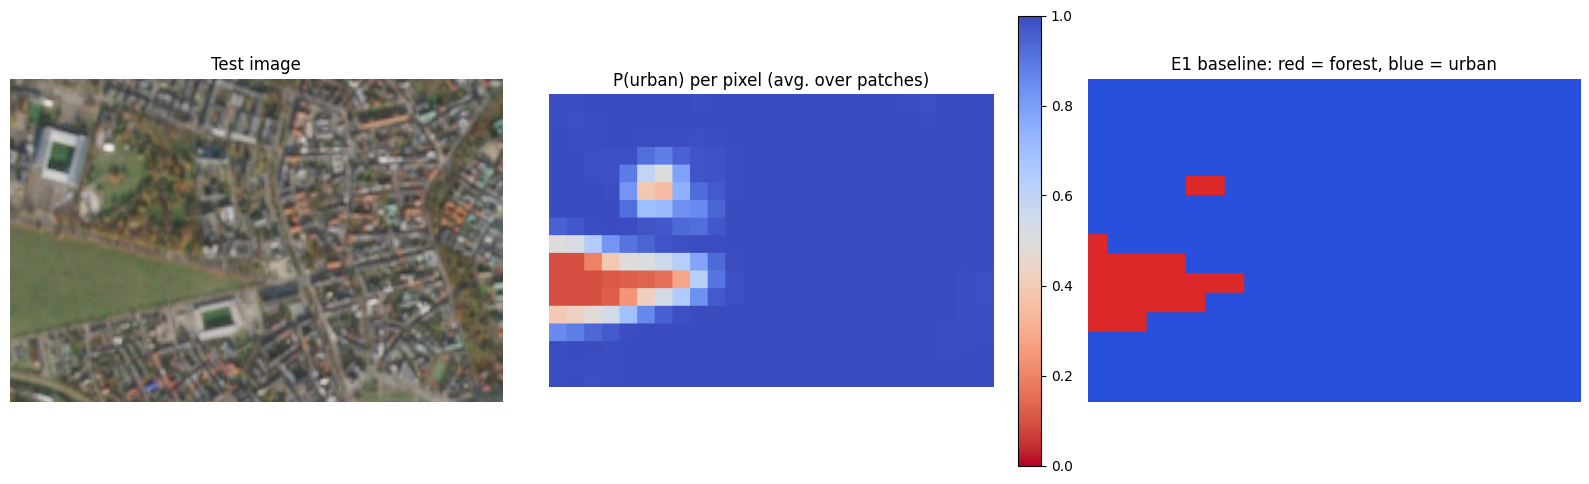

urban share of the test image: 94.0%


In [8]:
best = max(results, key=lambda n: results[n]["val_acc"][0])
print("Best on validation:", best)

def classify_image(img, predict, stride):
    H, W = img.shape[:2]
    if H < PATCH or W < PATCH:
        raise ValueError(f"test image {img.shape[:2]} is smaller than PATCH={PATCH}")
    rows = sorted(set(list(range(0, H - PATCH + 1, stride)) + [H - PATCH]))
    cols = sorted(set(list(range(0, W - PATCH + 1, stride)) + [W - PATCH]))
    pos = [(r, c) for r in rows for c in cols]
    p = predict(np.array([img[r:r + PATCH, c:c + PATCH] for r, c in pos]) / 255.0)
    acc, cnt = np.zeros((H, W)), np.zeros((H, W))
    for (r, c), pi in zip(pos, p):
        acc[r:r + PATCH, c:c + PATCH] += pi; cnt[r:r + PATCH, c:c + PATCH] += 1
    return acc / cnt

prob = classify_image(test_img, predictors[best], stride=max(PATCH // 2, 1))
labels = (prob > 0.5).astype(int)
colored = np.where((labels == FOREST)[..., None], RED, BLUE).astype(np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].imshow(test_img.astype(np.uint8)); ax[0].set_title("Test image")
im = ax[1].imshow(prob, cmap="coolwarm_r", vmin=0, vmax=1); ax[1].set_title("P(urban) per pixel (avg. over patches)")
plt.colorbar(im, ax=ax[1], fraction=0.046)
ax[2].imshow(colored); ax[2].set_title(f"{best.split(':')[0]}: red = forest, blue = urban")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print(f"urban share of the test image: {labels.mean():.1%}")

In this lab I trained a small ANN to classify patches of satellite imagery as forest or urban. The photos from the previous lab turned out to be too small for 200×200 patches, so the patch size was reduced automatically to 50×50 pixels. This gave 40 forest and 84 urban patches, split into 86 for training, 19 for validation and 19 for testing, with the training set augmented by flips and rotations. Five of the six architectures I tried reached 100 % accuracy on both validation and test data, with no spread between random initialisations. These were the baseline (one hidden layer of 32 nodes), 128 nodes, two layers, the SGD optimiser, and mean/std RGB features as input. The experiment therefore cannot rank them, because the task is too easy for this data. The changes only affected how quickly the validation loss fell: the two-layer network fell fastest, while the baseline was still improving after 80 epochs. The tanh variant reached only 68.4 %, but this was a training failure, not a property of the activation function. That figure equals the share of urban patches in the test set, so the network simply labelled everything as urban. A likely cause is that the tanh units saturated on the 7,500 unscaled inputs, though I did not test this. There was no sign of overfitting: training, validation and test accuracy were identical, and the validation loss kept decreasing. This is because the task is easy rather than because large networks are safe, and the validation and test patches come from the same two photos as the training patches, so this measures generalisation within these photos only. The Bayes classifier on mean RGB, which needs no iterative training and only 19 numbers, also scored 100 %. That matches networks with between 129 and 960,257 parameters, so the ANNs added computing cost but no accuracy. This is why a Bayesian classifier is preferable when classes are separable by colour. An ANN would only pay off in cases such as a green park inside a city, which this data does not contain. On the new image, the network labelled 94 % of a dense urban district as urban, which matches the picture. It marked the large grass field and a park area near the stadium as forest. This is reasonable, since "forest" here effectively means green vegetation. The boundaries are blocky and soft because each decision covers a 50-pixel patch, and green areas smaller than a patch, such as pitches, courtyards and tree-lined streets, are absorbed into the urban class. With no ground truth for the new image, the map could only be judged by eye. The main limitation is the small number of patches. With only 19 test patches, one patch equals 5.3 percentage points, and zero errors on 19 patches only suggests a true accuracy above about 84 %. The classes are also imbalanced, with a 68 % baseline from always predicting urban, and all patches come from just two photos. More reliable results would need more and larger images covering different scenes, a split by photo rather than by patch, k-fold cross-validation, class weighting, harder cases such as parks and suburbs, and a few hand-labelled patches of the test image to measure the accuracy of the map.